# X-ray Body Part Classification with VGG19 — Revised Experiment

**Task:** Multi-label prediction of 22 anatomical labels from X-ray images (UNIFESP X-ray Body Part Classifier).

**Revision from the original undergraduate notebook:** Replaces the accidental last-fold-only split with one explicitly multilabel-stratified train/validation split; prevents caching augmented images; reports multilabel F1 and per-class precision/recall. Uses TensorFlow/Keras-native augmentation and Adam to avoid compatibility issues with older TensorFlow Addons/Albumentations code. The VGG19 feature extractor and dense classification head are retained.

**Important:** This is a revised experiment. Original saved accuracy/logs do **not** represent results from this code. Run all cells to obtain fresh results. The competition test set has no labels; validation results are not independent held-out test results. Data is stored privately on Google Drive, not committed to GitHub.

## 1. Setup (Google Colab GPU)
Select **Runtime → Change runtime type → GPU**. Package installs may require a runtime restart.

In [2]:
!pip -q install iterative-stratification scikit-learn

In [3]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.metrics import f1_score, classification_report, precision_score, recall_score
from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

IMG_HEIGHT, IMG_WIDTH = 224, 224
BATCH_SIZE = 16
EPOCHS = 200
PATIENCE = 8
LEARNING_RATE = 1e-5
AUTOTUNE = tf.data.AUTOTUNE
print('TensorFlow:', tf.__version__)
print('GPUs:', tf.config.list_physical_devices('GPU'))

TensorFlow: 2.21.0
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [4]:
from google.colab import drive
drive.mount('/content/drive')

DATA_DIR = '/content/drive/MyDrive/DeepLearning'
TRAIN_DIR = os.path.join(DATA_DIR, 'train')
TEST_DIR = os.path.join(DATA_DIR, 'test')
assert os.path.isfile(os.path.join(DATA_DIR, 'train.csv')), 'Missing train.csv'
assert os.path.isdir(TRAIN_DIR), 'Missing train/ folder'

class_names = np.array([
    'Abdomen', 'Ankle', 'Cervical Spine', 'Chest', 'Clavicles',
    'Elbow', 'Feet', 'Finger', 'Forearm', 'Hand', 'Hip', 'Knee',
    'Lower Leg', 'Lumbar Spine', 'Others', 'Pelvis', 'Shoulder',
    'Sinus', 'Skull', 'Thigh', 'Thoracic Spine', 'Wrist'
])
NUM_CLASSES = len(class_names)
df = pd.read_csv(os.path.join(DATA_DIR, 'train.csv'))
print('CSV rows:', len(df), '| image files:', len(os.listdir(TRAIN_DIR)))
print(df.head(3).to_string(index=False))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
CSV rows: 1738 | image files: 1738
                                                  SOPInstanceUID Target
1.2.826.0.1.3680043.8.498.10025629581362719970278200333618114258     0 
1.2.826.0.1.3680043.8.498.10036150326276641158002573300029848125    15 
1.2.826.0.1.3680043.8.498.10038426859954986240523417641213777162    12 


## 2. Labels and multilabel-aware validation split
The original notebook used `StratifiedKFold` but only trained on its **last** fold. It also stratified on `argmax` of a multilabel target. Here we perform a single reproducible **multilabel-stratified 75/25 split**. This is not cross-validation.

In [5]:
def parse_labels(text):
    row = np.zeros(NUM_CLASSES, dtype=np.float32)
    for token in str(text).split():
        idx = int(token)
        if not 0 <= idx < NUM_CLASSES:
            raise ValueError(f'Unexpected label index: {idx}')
        row[idx] = 1.0
    return row

X = np.array([os.path.join(TRAIN_DIR, f'{uid}.png') for uid in df['SOPInstanceUID']], dtype=str)
y = np.stack([parse_labels(t) for t in df['Target']])
missing = [p for p in X if not os.path.isfile(p)]
assert not missing, f'Missing images; example: {missing[:3]}'

splitter = MultilabelStratifiedShuffleSplit(n_splits=1, test_size=0.25, random_state=SEED)
train_idx, valid_idx = next(splitter.split(X, y))
X_train, X_valid = X[train_idx], X[valid_idx]
y_train, y_valid = y[train_idx], y[valid_idx]
print('Train:', len(X_train), '| Validation:', len(X_valid))
label_counts = pd.DataFrame({
    'label': class_names,
    'train': y_train.sum(axis=0).astype(int),
    'validation': y_valid.sum(axis=0).astype(int)
})
display(label_counts)
print('Labels without positive validation examples:',
      label_counts.loc[label_counts['validation'] == 0, 'label'].tolist())

Train: 1302 | Validation: 436


,label,train,validation
0,Abdomen,69,23
1,Ankle,40,14
2,Cervical Spine,61,20
3,Chest,553,185
4,Clavicles,7,2
5,Elbow,19,6
6,Feet,58,20
7,Finger,13,4
8,Forearm,11,4
9,Hand,55,19


Labels without positive validation examples: []


## 3. Input pipeline and per-epoch augmentation
Decode and resize to 224×224. Apply randomized, mild intensity changes **only** to the training dataset. No `.cache()` after augmentation. Unlike the old notebook, no vertical flips are applied; changes that can affect anatomical laterality are avoided. VGG19 preprocessing is performed inside the model.

In [6]:
def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.io.decode_png(image, channels=1)
    image = tf.image.resize(tf.cast(image, tf.float32), [IMG_HEIGHT, IMG_WIDTH])
    image.set_shape([IMG_HEIGHT, IMG_WIDTH, 1])
    return image, tf.cast(label, tf.float32)

def augment_image(image, label):
    # Images remain in 0..255 scale for VGG19 preprocess_input.
    image = tf.image.random_brightness(image, max_delta=12.0)
    image = tf.image.random_contrast(image, lower=0.9, upper=1.1)
    image = tf.clip_by_value(image, 0.0, 255.0)
    return image, label

train_ds = (tf.data.Dataset.from_tensor_slices((X_train, y_train))
            .shuffle(len(X_train), seed=SEED, reshuffle_each_iteration=True)
            .map(load_image, num_parallel_calls=AUTOTUNE)
            .map(augment_image, num_parallel_calls=AUTOTUNE)
            .batch(BATCH_SIZE)
            .prefetch(AUTOTUNE))

valid_ds = (tf.data.Dataset.from_tensor_slices((X_valid, y_valid))
            .map(load_image, num_parallel_calls=AUTOTUNE)
            .batch(BATCH_SIZE)
            .prefetch(AUTOTUNE))

image_batch, label_batch = next(iter(train_ds))
print('Image batch:', image_batch.shape, '| Label batch:', label_batch.shape)

Image batch: (16, 224, 224, 1) | Label batch: (16, 22)


## 4. VGG19 transfer learning
Keep the same core topology as the original notebook: pretrained VGG19, freeze its first 13 layers, global average pooling, and the original dense-head sizes (512→256→128→128→22). Use an FP32 sigmoid output for stable probability estimates. TensorFlow Addons `RectifiedAdam` is replaced by built-in `Adam` to support contemporary Colab TensorFlow versions; therefore training results are not directly comparable to the original experiment.

In [7]:
# Set policy before constructing layers. Use default float32 if no GPU is available.
if tf.config.list_physical_devices('GPU'):
    tf.keras.mixed_precision.set_global_policy('mixed_float16')
else:
    tf.keras.mixed_precision.set_global_policy('float32')

base_model = tf.keras.applications.VGG19(
    input_shape=(IMG_HEIGHT, IMG_WIDTH, 3),
    include_top=False, weights='imagenet'
)
for layer in base_model.layers[:13]:
    layer.trainable = False

inputs = tf.keras.Input(shape=(IMG_HEIGHT, IMG_WIDTH, 1), name='xray_grayscale')
x = tf.keras.layers.Concatenate(axis=-1)([inputs, inputs, inputs])
x = tf.keras.layers.Lambda(
    tf.keras.applications.vgg19.preprocess_input, name='vgg19_preprocess'
)(x)
x = base_model(x)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dense(512, activation='relu')(x)
x = tf.keras.layers.Dense(256, activation='relu')(x)
x = tf.keras.layers.Dropout(0.5)(x)
x = tf.keras.layers.Dense(128, activation='relu')(x)
x = tf.keras.layers.Dense(128, activation='relu')(x)
outputs = tf.keras.layers.Dense(NUM_CLASSES, activation='sigmoid', dtype='float32')(x)
model = tf.keras.Model(inputs, outputs)
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE),
              loss=tf.keras.losses.BinaryCrossentropy(),
              metrics=[tf.keras.metrics.BinaryAccuracy(name='binary_accuracy')])
print('Trainable params:', sum(int(np.prod(v.shape)) for v in model.trainable_weights))

80134624/80134624 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step
Trainable params: 16964886


## 5. Train
There is no `.repeat()`: each epoch consumes every training example once, including the final partial batch. Validation uses **all** validation samples.

In [8]:
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss', patience=PATIENCE, restore_best_weights=True
)
history = model.fit(
    train_ds,
    validation_data=valid_ds,
    epochs=EPOCHS,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/200
82/82 ━━━━━━━━━━━━━━━━━━━━ 54s 351ms/step - binary_accuracy: 0.5574 - loss: 0.7061 - val_binary_accuracy: 0.7743 - val_loss: 0.5131
Epoch 2/200
82/82 ━━━━━━━━━━━━━━━━━━━━ 5s 63ms/step - binary_accuracy: 0.7655 - loss: 0.4838 - val_binary_accuracy: 0.9074 - val_loss: 0.2786
Epoch 3/200
82/82 ━━━━━━━━━━━━━━━━━━━━ 5s 63ms/step - binary_accuracy: 0.8577 - loss: 0.3360 - val_binary_accuracy: 0.9481 - val_loss: 0.1933
Epoch 4/200
82/82 ━━━━━━━━━━━━━━━━━━━━ 6s 70ms/step - binary_accuracy: 0.9021 - loss: 0.2606 - val_binary_accuracy: 0.9515 - val_loss: 0.1747
Epoch 5/200
82/82 ━━━━━━━━━━━━━━━━━━━━ 5s 65ms/step - binary_accuracy: 0.9253 - loss: 0.2188 - val_binary_accuracy: 0.9637 - val_loss: 0.1501
Epoch 6/200
82/82 ━━━━━━━━━━━━━━━━━━━━ 7s 86ms/step - binary_accuracy: 0.9394 - loss: 0.1848 - val_binary_accuracy: 0.9692 - val_loss: 0.1269
Epoch 7/200
82/82 ━━━━━━━━━━━━━━━━━━━━ 9s 67ms/step - binary_accuracy: 0.9492 - loss: 0.1658 - val_binary_accuracy: 0.9700 - val_loss: 0.1164
Epoc

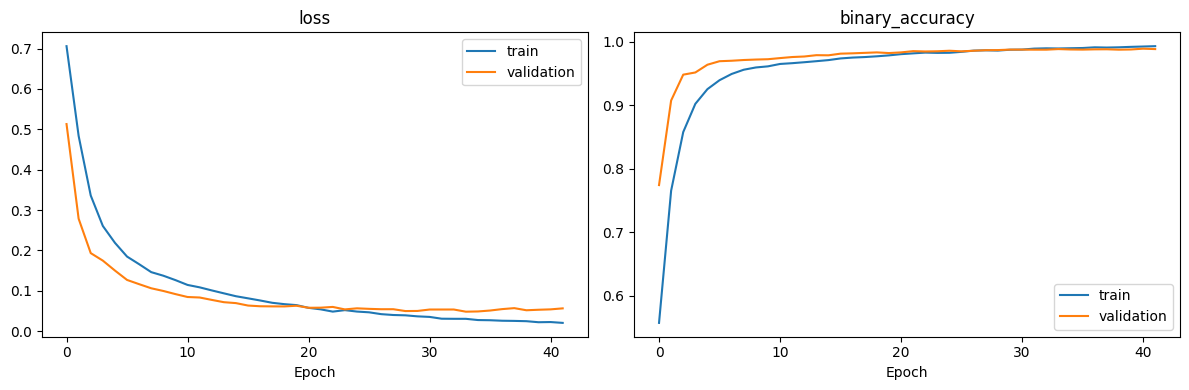

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metric in zip(axes, ['loss', 'binary_accuracy']):
    ax.plot(history.history[metric], label='train')
    ax.plot(history.history['val_' + metric], label='validation')
    ax.set_title(metric)
    ax.set_xlabel('Epoch')
    ax.legend()
plt.tight_layout()
plt.show()

## 6. Multilabel validation metrics
A high binary accuracy can be misleading when most class targets are zero. Report macro/micro F1 and per-class precision/recall, using a declared **0.5 threshold** (not tuned on validation). `valid_ds` does not shuffle, and predictions align with `y_valid`. If a class has zero validation positives, its recall/F1 is not independently interpretable.

In [11]:
validation_prob = model.predict(valid_ds, verbose=1)
assert validation_prob.shape == y_valid.shape, (validation_prob.shape, y_valid.shape)
validation_pred = (validation_prob >= 0.5).astype(np.int32)

print('Micro F1:     ', f1_score(y_valid, validation_pred, average='micro', zero_division=0))
print('Macro F1:     ', f1_score(y_valid, validation_pred, average='macro', zero_division=0))
print('Micro precision:', precision_score(y_valid, validation_pred, average='micro', zero_division=0))
print('Micro recall:   ', recall_score(y_valid, validation_pred, average='micro', zero_division=0))
print('\nPer-class validation report:')
print(classification_report(y_valid, validation_pred,
                            target_names=class_names, zero_division=0))

28/28 ━━━━━━━━━━━━━━━━━━━━ 7s 191ms/step
Micro F1:      0.8769230769230769
Macro F1:      0.7028885112961767
Micro precision: 0.9130434782608695
Micro recall:    0.8435517970401691

Per-class validation report:
                precision    recall  f1-score   support

       Abdomen       0.91      0.87      0.89        23
         Ankle       0.67      0.57      0.62        14
Cervical Spine       1.00      0.80      0.89        20
         Chest       0.99      0.97      0.98       185
     Clavicles       1.00      1.00      1.00         2
         Elbow       1.00      0.17      0.29         6
          Feet       0.95      0.90      0.92        20
        Finger       1.00      1.00      1.00         4
       Forearm       0.00      0.00      0.00         4
          Hand       0.94      0.89      0.92        19
           Hip       0.00      0.00      0.00         6
          Knee       1.00      0.93      0.96        28
     Lower Leg       1.00      0.43      0.60         7
  Lu

## 7. Optional: competition test predictions
The competition `test/` images have no labels in `sample_submission.csv`; do not report test F1/accuracy. The submission rule below follows the original notebook (0.9 confidence threshold; fall back to argmax), which is **different** from the 0.5 validation threshold. Only use it if you explicitly want to reproduce that submission heuristic.

In [10]:
# Optional — uncomment to create a Kaggle submission after successful training.
# submission = pd.read_csv(os.path.join(DATA_DIR, 'sample_submission.csv'))
# X_test = np.array([os.path.join(TEST_DIR, f'{uid}.png') for uid in submission['SOPInstanceUID']])
# assert all(os.path.isfile(p) for p in X_test)
# test_ds = (tf.data.Dataset.from_tensor_slices((X_test, np.zeros((len(X_test), NUM_CLASSES), dtype=np.float32)))
#            .map(load_image, num_parallel_calls=AUTOTUNE)
#            .batch(BATCH_SIZE).prefetch(AUTOTUNE))
# test_prob = model.predict(test_ds)
# submission['Target'] = [' '.join(map(str, np.flatnonzero(row > 0.9)))
#                          if np.any(row > 0.9) else str(np.argmax(row)) for row in test_prob]
# submission.to_csv('/content/vgg19_submission.csv', index=False)

## Interpretation and limitations

- This is a **newly revised** experimental setup, not a rerun of the original saved logs; results must be obtained by executing this notebook.
- The split is multilabel-stratified but is still **one** train/validation split; no cross-validation or independent labeled test evaluation is claimed.
- The dataset has 1,738 labeled images (as confirmed in the original Google Drive folder); label frequencies may be sparse.
- Validation metrics may be sensitive to sample splitting and to the fixed probability threshold. No external clinical validation is performed.
- Neither the model nor this project is intended for medical decision-making.
- Check Kaggle competition data terms before redistributing X-ray images or model outputs.
